# Indian Data Analyst Job Market Analytics

**Author:** Vivek Saini — Data Analyst (SQL · Python · Excel · Power BI)

## The question
*What does the Indian job market actually reward in a Data Analyst — and how should a candidate prioritise skills, cities, and experience to maximise their chances and salary?*

Instead of guessing, this project analyses **1,200 job postings** for Data Analyst, Business Analyst, and MIS Executive roles across 10 Indian cities to answer:

1. Which skills are demanded most?
2. How much does experience move salary?
3. Which cities pay the most?
4. Which skills carry a salary *premium*?
5. Who is hiring — and how do they work (remote / hybrid / on-site)?

> **A note on the data:** the dataset is *synthetically generated* (see `generate_data.py`, seed 42) with fictional companies and salary structures modelled on real Indian market patterns (fresher ≈ ₹3–6 LPA, senior ≈ ₹12–22 LPA, Tier-1 city premium, skill premiums). It demonstrates a complete, reproducible analytics workflow — data generation, cleaning, analysis, and visualisation — without misrepresenting synthetic numbers as scraped market truth.

**Tools:** Python, pandas, matplotlib, seaborn · **Companion files:** `analysis.py` (same analysis as a script), `findings.json`, `charts/`

## 1 · Setup — load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
pd.set_option("display.max_columns", 20)

df = pd.read_csv("data/job_postings.csv")
print(f"Postings loaded: {len(df):,}")
df.head()

Postings loaded: 1,200


,job_id,job_title,company,city,exp_min_yrs,exp_max_yrs,salary_min_lpa,salary_max_lpa,skills,company_type,work_mode,posted_date
0,JMA-0332,Business Analyst,LumenArc Analytics,Delhi NCR,0,0,4.5,6.0,Data Modeling;Communication;Statistics;Power Q...,MNC,On-site,2026-10-19
1,JMA-0863,MIS Executive,Crestline Technologies,Bengaluru,1,3,7.5,9.0,Excel;Power Query;Stakeholder Management,Startup,Hybrid,2026-10-19
2,JMA-0337,Analytics Associate,InsightForge Solutions,Mumbai,5,7,14.0,19.0,Excel;SQL;Data Modeling;Statistics;Power BI;Ta...,Startup,On-site,2026-10-19
3,JMA-0223,Senior Data Analyst,PrimeVector Technologies,Chennai,0,0,4.5,6.5,Excel;SQL;Data Modeling;Communication;Python;P...,Mid-size,On-site,2026-10-19
4,JMA-0503,Data Analyst,FluxWorks Labs,Chennai,1,3,7.0,9.5,Power Query;Power BI;Communication;SQL;Python;...,Startup,Remote,2026-10-19


## 2 · Data overview & feature engineering

Each row is one posting: title, company, city, experience range, salary range (₹ LPA), a semicolon-separated skills list, company type, work mode, and posted date.

In [2]:
df.info()
print("\nNull values per column:")
print(df.isna().sum().to_string())

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   job_id          1200 non-null   str    
 1   job_title       1200 non-null   str    
 2   company         1200 non-null   str    
 3   city            1200 non-null   str    
 4   exp_min_yrs     1200 non-null   int64  
 5   exp_max_yrs     1200 non-null   int64  
 6   salary_min_lpa  1200 non-null   float64
 7   salary_max_lpa  1200 non-null   float64
 8   skills          1200 non-null   str    
 9   company_type    1200 non-null   str    
 10  work_mode       1200 non-null   str    
 11  posted_date     1200 non-null   str    
dtypes: float64(2), int64(2), str(8)
memory usage: 112.6 KB

Null values per column:
job_id            0
job_title         0
company           0
city              0
exp_min_yrs       0
exp_max_yrs       0
salary_min_lpa    0
salary_max_lpa    0
skills            0
company_t

In [3]:
# Derived features used throughout the analysis
df["salary_avg"] = (df["salary_min_lpa"] + df["salary_max_lpa"]) / 2   # midpoint of posted range
df["exp_mid"]    = (df["exp_min_yrs"] + df["exp_max_yrs"]) / 2        # midpoint of experience range
df["n_skills"]   = df["skills"].str.split(";").str.len()             # number of skills listed

def exp_band(r):
    if r["exp_max_yrs"] <= 1:  return "0\u20131 yrs (Fresher)"
    if r["exp_min_yrs"] >= 5:  return "5+ yrs"
    if r["exp_min_yrs"] >= 3:  return "3\u20135 yrs"
    return "1\u20133 yrs"

df["exp_band"] = df.apply(exp_band, axis=1)
BAND_ORDER = ["0\u20131 yrs (Fresher)", "1\u20133 yrs", "3\u20135 yrs", "5+ yrs"]

df[["job_title", "city", "salary_avg", "exp_mid", "exp_band", "n_skills"]].head()

,job_title,city,salary_avg,exp_mid,exp_band,n_skills
0,Business Analyst,Delhi NCR,5.25,0.0,0–1 yrs (Fresher),6
1,MIS Executive,Bengaluru,8.25,2.0,1–3 yrs,3
2,Analytics Associate,Mumbai,16.50,6.0,5+ yrs,6
3,Senior Data Analyst,Chennai,5.50,0.0,0–1 yrs (Fresher),7
4,Data Analyst,Chennai,8.25,2.0,1–3 yrs,6


In [4]:
print("Postings by role:")
print(df["job_title"].value_counts().to_string())
print("\nPostings by experience band:")
print(df["exp_band"].value_counts().reindex(BAND_ORDER).to_string())
print(f"\nOverall median salary: \u20b9{df['salary_avg'].median():.1f} LPA")

Postings by role:
job_title
Data Analyst           651
Business Analyst       169
MIS Executive          163
Senior Data Analyst    136
Analytics Associate     81

Postings by experience band:
exp_band
0–1 yrs (Fresher)    236
1–3 yrs              451
3–5 yrs              360
5+ yrs               153

Overall median salary: ₹8.8 LPA


## 3 · Which skills are in demand?

Counting skills across all postings (each posting lists several) shows what employers ask for again and again.

In [5]:
exploded = df.assign(skill=df["skills"].str.split(";")).explode("skill")
skill_counts = exploded["skill"].value_counts()

top15 = (skill_counts.head(15)
         .rename_axis("skill").reset_index(name="postings"))
top15["share_of_postings_%"] = (top15["postings"] / len(df) * 100).round(1)
top15

,skill,postings,share_of_postings_%
0,SQL,1086,90.5
1,Excel,1072,89.3
2,Communication,677,56.4
3,Power BI,610,50.8
4,Python,570,47.5
5,Statistics,563,46.9
6,Power Query,463,38.6
7,Data Modeling,343,28.6
8,Stakeholder Management,333,27.8
9,Tableau,332,27.7


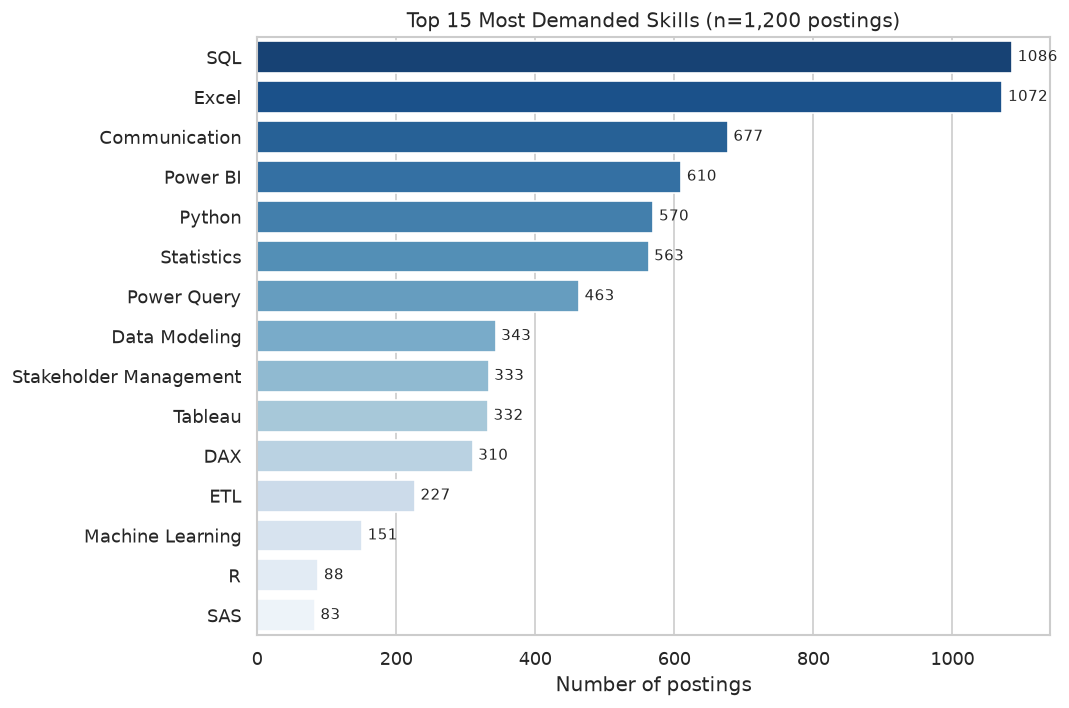

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=top15, x="postings", y="skill", hue="skill",
            palette="Blues_r", legend=False, ax=ax)
ax.set_title("Top 15 Most Demanded Skills (n=1,200 postings)")
ax.set_xlabel("Number of postings"); ax.set_ylabel("")
for i, v in enumerate(top15["postings"]):
    ax.text(v + 8, i, str(v), va="center", fontsize=9)
plt.tight_layout(); plt.show()

**Takeaway:** **SQL (90.5%)** and **Excel (89.3%)** appear in almost every posting — they are the non-negotiable core. Python follows, and **Communication (56.4%)** shows soft skills are a real hiring filter, not filler text.

## 4 · How much does experience pay?

Grouping postings into experience bands and comparing median salaries:

In [7]:
med_band = df.groupby("exp_band")["salary_avg"].median().reindex(BAND_ORDER)
med_band.rename("median_salary_lpa").reset_index()

,exp_band,median_salary_lpa
0,0–1 yrs (Fresher),4.75
1,1–3 yrs,8.25
2,3–5 yrs,12.75
3,5+ yrs,18.75


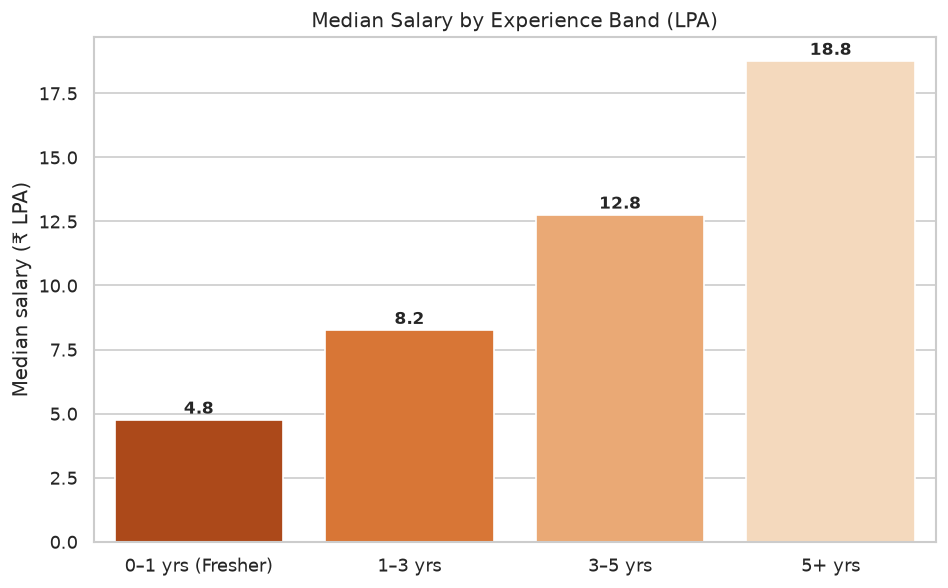

Correlation(experience midpoint, salary) = 0.96


In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=med_band.index, y=med_band.values, hue=med_band.index,
            palette="Oranges_r", legend=False, ax=ax)
ax.set_title("Median Salary by Experience Band (LPA)")
ax.set_ylabel("Median salary (\u20b9 LPA)"); ax.set_xlabel("")
for i, v in enumerate(med_band.values):
    ax.text(i, v + 0.25, f"{v:.1f}", ha="center", fontsize=10, fontweight="bold")
plt.tight_layout(); plt.show()

corr = df["exp_mid"].corr(df["salary_avg"])
print(f"Correlation(experience midpoint, salary) = {corr:.2f}")

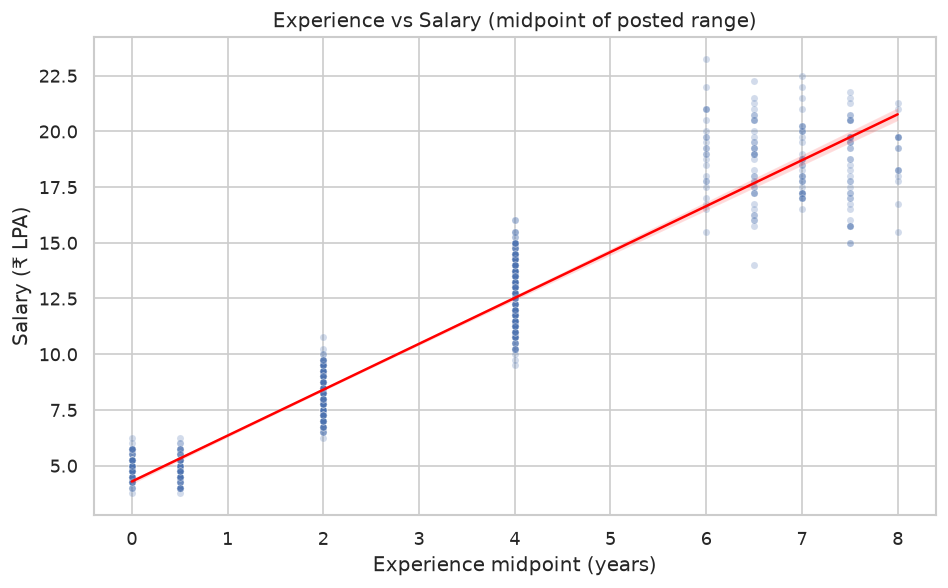

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x="exp_mid", y="salary_avg", alpha=0.25, s=18, ax=ax)
sns.regplot(data=df, x="exp_mid", y="salary_avg", scatter=False,
            color="red", line_kws={"linewidth": 1.5}, ax=ax)
ax.set_title("Experience vs Salary (midpoint of posted range)")
ax.set_xlabel("Experience midpoint (years)"); ax.set_ylabel("Salary (\u20b9 LPA)")
plt.tight_layout(); plt.show()

**Takeaway:** median pay climbs from **₹4.8 LPA (fresher)** to **₹18.8 LPA (5+ yrs)** — a **~3.9× jump**, with a very strong experience–salary correlation (**0.96**). Early-career takeaway: the first 3–5 years compound fast, so optimise for learning roles early.

## 5 · Which cities pay the most?

In [10]:
med_city = df.groupby("city")["salary_avg"].median().sort_values(ascending=False)
med_city.rename("median_salary_lpa").reset_index()

,city,median_salary_lpa
0,Mumbai,9.250
1,Bengaluru,9.000
2,Delhi NCR,9.000
3,Chennai,8.875
4,Pune,8.750
5,Hyderabad,8.750
6,Jaipur,8.125
7,Ahmedabad,8.000
8,Lucknow,8.000
9,Kolkata,7.875


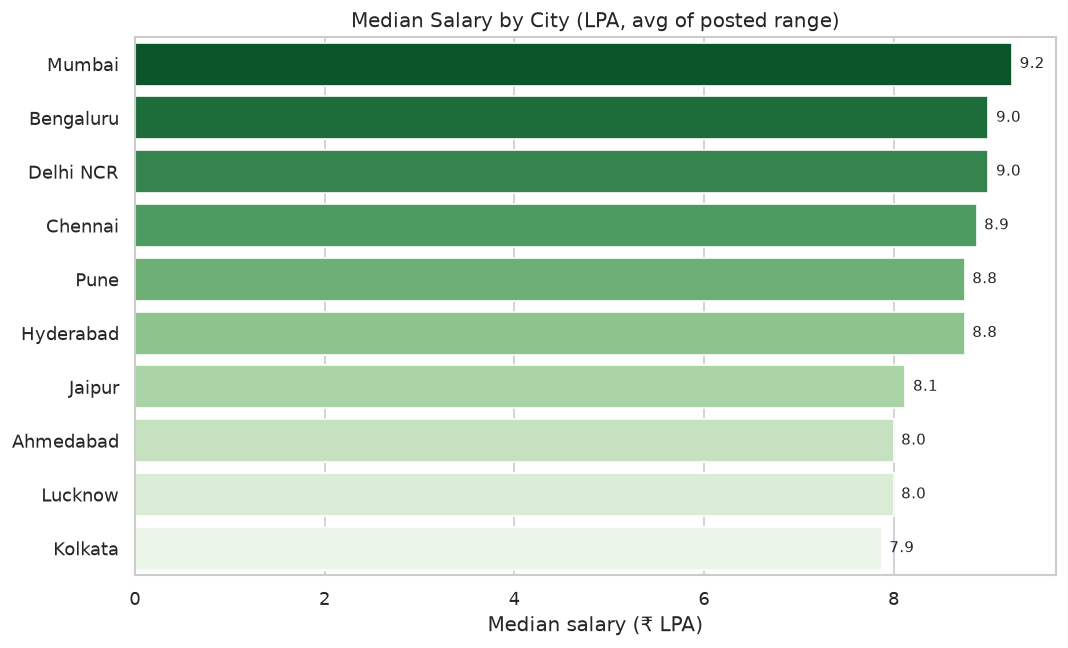

In [11]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(x=med_city.values, y=med_city.index, hue=med_city.index,
            palette="Greens_r", legend=False, ax=ax)
ax.set_title("Median Salary by City (LPA, avg of posted range)")
ax.set_xlabel("Median salary (\u20b9 LPA)"); ax.set_ylabel("")
for i, v in enumerate(med_city.values):
    ax.text(v + 0.08, i, f"{v:.1f}", va="center", fontsize=9)
plt.tight_layout(); plt.show()

**Takeaway:** Tier-1 cities lead — **Mumbai ₹9.2 LPA**, Bengaluru and Delhi NCR ₹9.0 LPA — while **Kolkata (₹7.9 LPA)** trails by ₹1.3 LPA. Worth weighing against cost of living before relocating for a headline number.

## 6 · Which skills carry a salary premium?

For each skill: median salary of postings that list it, minus the overall median (₹8.8 LPA). A positive value means the skill is associated with better-paid roles.

In [12]:
overall_median = df["salary_avg"].median()
prem = {sk: round(grp["salary_avg"].median() - overall_median, 2)
        for sk, grp in exploded.groupby("skill")}
prem_s = pd.Series(prem).sort_values(ascending=False)
prem_s.head(10).rename("premium_lpa").reset_index().rename(columns={"index": "skill"})

,skill,premium_lpa
0,Machine Learning,3.00
1,Data Modeling,0.50
2,Python,0.50
3,SQL,0.25
4,Statistics,0.25
5,Tableau,0.25
6,ETL,0.25
7,Power BI,0.00
8,Excel,0.00
9,Communication,0.00


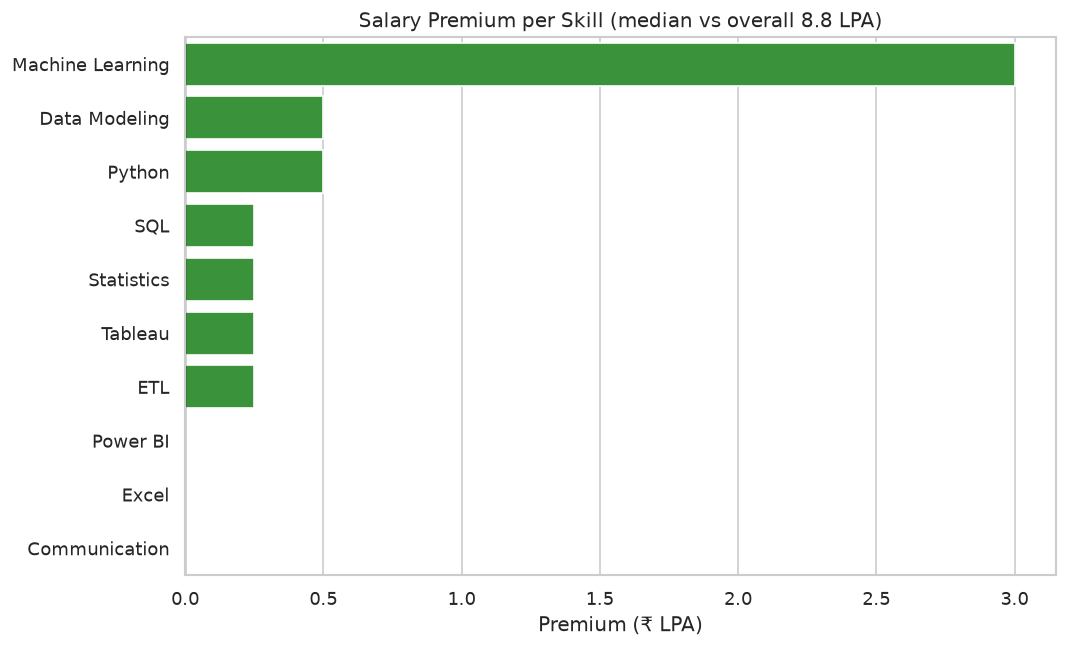

Median experience required — ML postings: 4.0 yrs | all postings: 2.0 yrs


In [13]:
top_prem = prem_s.head(10)
colors = ["#2ca02c" if v >= 0 else "#d62728" for v in top_prem.values]
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(x=top_prem.values, y=top_prem.index, hue=top_prem.index,
            palette=colors, legend=False, ax=ax)
ax.set_title(f"Salary Premium per Skill (median vs overall {overall_median:.1f} LPA)")
ax.set_xlabel("Premium (\u20b9 LPA)"); ax.set_ylabel("")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout(); plt.show()

ml_exp = exploded[exploded["skill"] == "Machine Learning"]["exp_mid"].median()
print(f"Median experience required — ML postings: {ml_exp:.1f} yrs | all postings: {df['exp_mid'].median():.1f} yrs")

**Takeaway — with a caveat:** **Machine Learning shows the biggest premium (+₹2.95 LPA)**, but ML postings also demand a median **4.0 years** of experience vs **2.0 years** overall — part of the "premium" is seniority, not the skill alone. Honest analysis means naming confounders like this.

## 7 · Who is hiring — and how do they work?

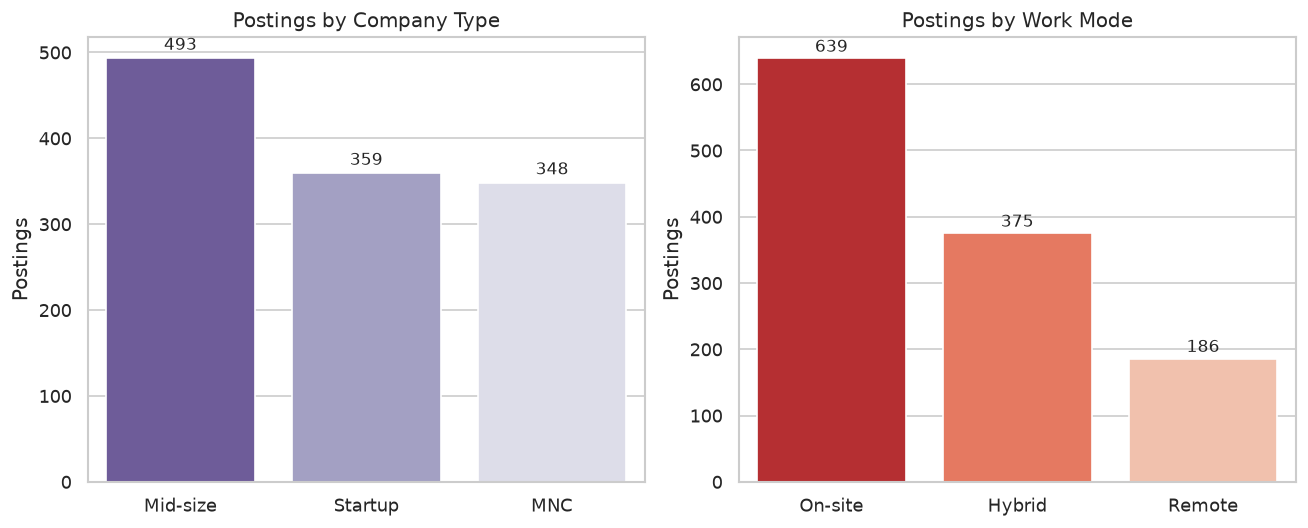

Work-mode share: {'On-site': '53.2%', 'Hybrid': '31.2%', 'Remote': '15.5%'}
Correlation(number of listed skills, salary) = 0.06


In [14]:
ctype_counts = df["company_type"].value_counts()
wmode_counts = df["work_mode"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.barplot(x=ctype_counts.index, y=ctype_counts.values, hue=ctype_counts.index,
            ax=axes[0], palette="Purples_r", legend=False)
axes[0].set_title("Postings by Company Type"); axes[0].set_ylabel("Postings"); axes[0].set_xlabel("")
for i, v in enumerate(ctype_counts.values):
    axes[0].text(i, v + 10, str(v), ha="center", fontsize=10)
sns.barplot(x=wmode_counts.index, y=wmode_counts.values, hue=wmode_counts.index,
            ax=axes[1], palette="Reds_r", legend=False)
axes[1].set_title("Postings by Work Mode"); axes[1].set_ylabel("Postings"); axes[1].set_xlabel("")
for i, v in enumerate(wmode_counts.values):
    axes[1].text(i, v + 10, str(v), ha="center", fontsize=10)
plt.tight_layout(); plt.show()

print("Work-mode share:", {k: f"{v/len(df)*100:.1f}%" for k, v in wmode_counts.items()})
print(f"Correlation(number of listed skills, salary) = {df['n_skills'].corr(df['salary_avg']):.2f}")

**Takeaway:** **on-site still dominates (53.2%)**, hybrid is 31.2%, and only **15.5% of roles are fully remote**. And listing *more* skills barely correlates with pay (0.06) — **which** skills you have matters, not how many.

## 8 · Key findings

1. **SQL is non-negotiable** — in 90.5% of 1,200 postings; Excel is close behind at 89.3%.
2. **Experience pays steeply** — median salary rises ~3.9× from fresher (₹4.8 LPA) to 5+ years (₹18.8 LPA); correlation 0.96.
3. **Tier-1 cities pay more** — Mumbai ₹9.2 LPA median vs Kolkata ₹7.9 LPA.
4. **Machine Learning carries the largest skill premium** (+₹2.95 LPA), partly confounded by seniority.
5. **Remote work is scarce** — 15.5% of postings; on-site remains the default.
6. **Skill quality beats quantity** — number of listed skills correlates with salary at only 0.06.

## 9 · Conclusion

For a fresher entering this market, the data points to a clear strategy: **master SQL + Excel + one BI tool first**, treat Python as the multiplier, and don't chase remote-only roles. 

---
*Reproduce everything:* run `python generate_data.py` → `python analysis.py`, or execute this notebook top to bottom. All findings are also stored in `findings.json`.